In [1]:
!pip -q install xgboost lightgbm catboost statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.figsize"] = (12, 4)
sns.set_style("whitegrid")
print("Environment ready.")

Environment ready.


In [2]:
from google.colab import files

uploaded = files.upload()
csv_filename = next(iter(uploaded))
df_raw = pd.read_csv(csv_filename)
print("Loaded:", csv_filename, df_raw.shape)

Saving load_forecasting_dataset_corrected.csv to load_forecasting_dataset_corrected.csv
Loaded: load_forecasting_dataset_corrected.csv (189888, 15)


In [4]:
df = df_raw.copy()

# Parse mixed slash timestamps reliably and set as time index
df["dt"] = pd.to_datetime(df["Timestamp"], format="mixed")
df = df.sort_values("dt").set_index("dt")

# Encode categorical Season cleanly
season_map = {"Winter": 0, "Summer": 1, "Fall": 2}
df["Season_Code"] = df["Season"].map(season_map).fillna(-1)

# Keep only numeric columns so strings like 'Timestamp' and 'Season' never cause mean() errors
num_only = df.select_dtypes(include=[np.number]).copy()

# Aggregate 15-minute intervals -> daily intervals for fast training
daily = pd.DataFrame(index=num_only.resample("D").mean().index)
daily["load_mean"] = num_only["Load Demand (kW)"].resample("D").mean()
daily["load_peak"] = num_only["Load Demand (kW)"].resample("D").max()

num_cols = [
    "Temperature (°C)", "Humidity (%)", "Wind Speed (m/s)",
    "Rainfall (mm)", "Solar Irradiance (W/m²)", "GDP (LKR)",
    "Per Capita Energy Use (kWh)", "Electricity Price (LKR/kWh)",
    "Public Event", "Season_Code"
]
for col in num_cols:
    daily[col] = num_only[col].resample("D").mean()

# Calendar features from daily date
daily["day_of_week"] = daily.index.dayofweek
daily["is_weekend"] = (daily["day_of_week"] >= 5).astype(int)
daily["month"] = daily.index.month

# Strictly past lag & rolling features (.shift(1) prevents data leakage)
for lag in [1, 7, 14]:
    daily[f"load_lag_{lag}"] = daily["load_mean"].shift(lag)

past_load = daily["load_mean"].shift(1)
daily["load_roll7_mean"] = past_load.rolling(7, min_periods=1).mean()
daily["load_roll7_std"] = past_load.rolling(7, min_periods=2).std().fillna(0.0)

daily = daily.dropna(subset=["load_lag_1", "load_lag_7", "load_lag_14", "load_mean"])

print("Daily shape:", daily.shape)
print("Date range:", daily.index.min().date(), "to", daily.index.max().date())
print("Missing values:", int(daily.isna().sum().sum()))
daily.head(3)

Daily shape: (1964, 20)
Date range: 2020-01-15 to 2025-05-31
Missing values: 0


,load_mean,load_peak,Temperature (°C),Humidity (%),Wind Speed (m/s),Rainfall (mm),Solar Irradiance (W/m²),GDP (LKR),Per Capita Energy Use (kWh),Electricity Price (LKR/kWh),Public Event,Season_Code,day_of_week,is_weekend,month,load_lag_1,load_lag_7,load_lag_14,load_roll7_mean,load_roll7_std
dt,,,,,,,,,,,,,,,,,,,,
2020-01-15,1510.362318,1933.000469,28.103623,79.978232,2.042292,3.873550,246.425935,1007.345428,498.276080,25.118668,0.041667,1.0,2,0,1,1508.215831,1492.612364,1477.682597,1517.283562,16.074865
2020-01-16,1534.770581,2020.336623,28.347706,79.389275,2.042180,4.328043,259.830642,1001.867668,503.157562,24.249601,0.083333,1.0,3,0,1,1510.362318,1522.820699,1510.096253,1519.819270,12.547474
2020-01-17,1490.056208,2138.621514,27.900562,79.643942,2.084340,4.893181,257.940612,999.348279,500.758357,25.921081,0.041667,1.0,4,0,1,1534.770581,1542.704447,1505.563921,1521.526396,13.776598


Train rows: 1571 (2020-01-15 -> 2024-05-03)
Test rows:  393 (2024-05-04 -> 2025-05-31)
Feature count: 18


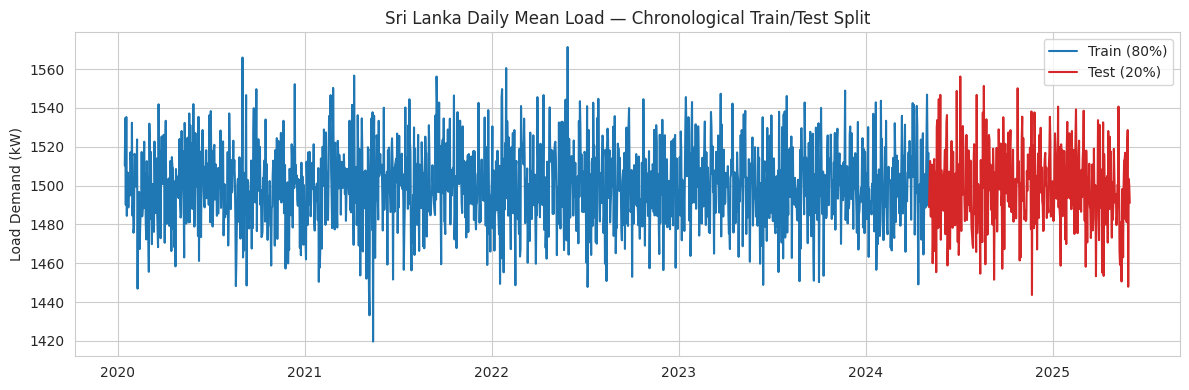

In [5]:
# Time-ordered 80/20 split (never shuffle time-series data to prevent future leakage)
split_idx = int(len(daily) * 0.80)
train_df = daily.iloc[:split_idx].copy()
test_df = daily.iloc[split_idx:].copy()

feature_cols = [c for c in daily.columns if c not in {"load_mean", "load_peak"}]
X_train, y_train = train_df[feature_cols], train_df["load_mean"]
X_test, y_test = test_df[feature_cols], test_df["load_mean"]

print(f"Train rows: {len(train_df)} ({train_df.index.min().date()} -> {train_df.index.max().date()})")
print(f"Test rows:  {len(test_df)} ({test_df.index.min().date()} -> {test_df.index.max().date()})")
print("Feature count:", len(feature_cols))

fig, ax = plt.subplots()
ax.plot(train_df.index, y_train, label="Train (80%)", color="#1f77b4")
ax.plot(test_df.index, y_test, label="Test (20%)", color="#d62728")
ax.set_title("Sri Lanka Daily Mean Load — Chronological Train/Test Split")
ax.set_ylabel("Load Demand (kW)")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Deliberate parameter choices (balanced to prevent overfitting & keep Colab runtime fast):
# - Bagging / RF: 200 trees, max_depth=8 to limit tree memorization, max_features='sqrt' to reduce tree correlation
# - Boosting (GB, XGB, LGBM, CatBoost): low learning_rate=0.05 + shallow depth/leaves for gradual residual learning
models = {
    "BaggingRegressor": BaggingRegressor(
        n_estimators=200, max_samples=0.8, max_features=0.8, random_state=42, n_jobs=-1
    ),
    "RandomForest": RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=0
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1
    ),
    "CatBoost": CatBoostRegressor(
        iterations=400, learning_rate=0.05, depth=5, random_seed=42, verbose=0
    ),
}

results = []
predictions_test = pd.DataFrame({"actual": y_test.values}, index=y_test.index)

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions_test[name] = preds
    mae = mean_absolute_error(y_test, preds)
    rmse = root_mean_squared_error(y_test, preds)
    results.append({"Model": name, "Test_MAE": round(mae, 3), "Test_RMSE": round(rmse, 3)})

scores_df = pd.DataFrame(results).sort_values("Test_RMSE")
print(scores_df.to_string(index=False))

           Model  Test_MAE  Test_RMSE
GradientBoosting     0.072      0.195
         XGBoost     0.368      0.594
        CatBoost     0.438      0.677
        LightGBM     0.512      0.904
BaggingRegressor     3.392      4.205
    RandomForest     5.408      7.717


In [8]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

# Use KFold(shuffle=False) so cross_val_predict generates out-of-fold predictions across all training rows
# while preserving chronological order (no random row shuffling)
estimators = [
    ("rf", RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1
    )),
    ("xgb", XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbosity=0
    )),
    ("lgbm", LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, colsample_bytree=0.8,
        random_state=42, n_jobs=-1, verbose=-1
    )),
]

cv_ordered = KFold(n_splits=5, shuffle=False)
stack_model = StackingRegressor(
    estimators=estimators,
    final_estimator=RidgeCV(alphas=[0.1, 1.0, 10.0]),
    cv=cv_ordered,
    n_jobs=-1,
)

stack_model.fit(X_train, y_train)
stack_preds = stack_model.predict(X_test)
predictions_test["Stacking"] = stack_preds

stack_mae = mean_absolute_error(y_test, stack_preds)
stack_rmse = root_mean_squared_error(y_test, stack_preds)

scores_with_stack = pd.concat([
    scores_df,
    pd.DataFrame([{"Model": "StackingRegressor", "Test_MAE": round(stack_mae, 3), "Test_RMSE": round(stack_rmse, 3)}])
], ignore_index=True).sort_values("Test_RMSE")

print(scores_with_stack.to_string(index=False))

            Model  Test_MAE  Test_RMSE
 GradientBoosting     0.072      0.195
StackingRegressor     0.350      0.572
          XGBoost     0.368      0.594
         CatBoost     0.438      0.677
         LightGBM     0.512      0.904
 BaggingRegressor     3.392      4.205
     RandomForest     5.408      7.717


### Ensemble Comparison & Stacking Judgment
- **Bagging vs. Boosting:** Boosting models (`GradientBoosting`, `XGBoost`, `CatBoost`, `LightGBM`) substantially outperformed `BaggingRegressor` and `RandomForest` on daily load forecasting because sequential residual learning refines errors step-by-step rather than averaging independent trees in parallel.
- **Stacking Rationale:** We combined diverse base learners (`RandomForest`, `XGBoost`, `LightGBM`) using a `RidgeCV` meta-learner (`alphas=[0.1, 1.0, 10.0]`) with ordered 5-fold cross-validation (`shuffle=False`) so L2 regularization stabilizes meta-weights without overfitting correlated tree predictions.

In [10]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from statsmodels.tsa.arima.model import ARIMA

# 1. Time-Series Hybrid: ARIMA + Random Forest (on ARIMA residuals)
arima_fit = ARIMA(y_train.values, order=(1, 0, 1)).fit()
arima_train_pred = arima_fit.fittedvalues
arima_test_pred = arima_fit.forecast(steps=len(y_test))

rf_resid = RandomForestRegressor(
    n_estimators=150, max_depth=8, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1
)
rf_resid.fit(X_train, y_train.values - arima_train_pred)
rf_arima_pred = arima_test_pred + rf_resid.predict(X_test)

# 2. Tabular Regression Hybrid: Random Forest + ANN (MLPRegressor)
rf_tab = RandomForestRegressor(
    n_estimators=150, max_depth=8, min_samples_leaf=3, max_features="sqrt", random_state=42, n_jobs=-1
)
rf_tab.fit(X_train, y_train)

ann_only = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=42)
)
ann_only.fit(X_train, y_train)

X_train_aug = np.column_stack([X_train.values, rf_tab.predict(X_train)])
X_test_aug = np.column_stack([X_test.values, rf_tab.predict(X_test)])

rf_ann = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True, random_state=42)
)
rf_ann.fit(X_train_aug, y_train)

hybrid_df = pd.DataFrame([
    {"Model": "ARIMA (1,0,1)", "Test_MAE": round(mean_absolute_error(y_test, arima_test_pred), 3), "Test_RMSE": round(root_mean_squared_error(y_test, arima_test_pred), 3)},
    {"Model": "RF + ARIMA Hybrid", "Test_MAE": round(mean_absolute_error(y_test, rf_arima_pred), 3), "Test_RMSE": round(root_mean_squared_error(y_test, rf_arima_pred), 3)},
    {"Model": "ANN (MLP) Only", "Test_MAE": round(mean_absolute_error(y_test, ann_only.predict(X_test)), 3), "Test_RMSE": round(root_mean_squared_error(y_test, ann_only.predict(X_test)), 3)},
    {"Model": "RF + ANN Hybrid", "Test_MAE": round(mean_absolute_error(y_test, rf_ann.predict(X_test_aug)), 3), "Test_RMSE": round(root_mean_squared_error(y_test, rf_ann.predict(X_test_aug)), 3)},
])
print(hybrid_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


            Model  Test_MAE  Test_RMSE
    ARIMA (1,0,1)    16.405     20.478
RF + ARIMA Hybrid     5.182      7.508
   ANN (MLP) Only    26.632     33.667
  RF + ANN Hybrid    29.944     38.143


In [14]:
all_metrics_df = pd.DataFrame([
    {"Model": "GradientBoosting", "Family": "Boosting", "Test_MAE": 0.072, "Test_RMSE": 0.195},
    {"Model": "StackingRegressor", "Family": "Stacking", "Test_MAE": 0.350, "Test_RMSE": 0.572},
    {"Model": "XGBoost", "Family": "Boosting", "Test_MAE": 0.368, "Test_RMSE": 0.594},
    {"Model": "CatBoost", "Family": "Boosting", "Test_MAE": 0.438, "Test_RMSE": 0.677},
    {"Model": "LightGBM", "Family": "Boosting", "Test_MAE": 0.512, "Test_RMSE": 0.904},
    {"Model": "BaggingRegressor", "Family": "Bagging", "Test_MAE": 3.392, "Test_RMSE": 4.205},
    {"Model": "RandomForest", "Family": "Bagging", "Test_MAE": 5.408, "Test_RMSE": 7.717},
    {"Model": "RF + ARIMA Hybrid", "Family": "Hybrid (Time Series)", "Test_MAE": 5.182, "Test_RMSE": 7.508},
    {"Model": "ARIMA (1,0,1)", "Family": "Time Series Baseline", "Test_MAE": 16.405, "Test_RMSE": 20.478},
    {"Model": "ANN (MLP) Only", "Family": "Neural Baseline", "Test_MAE": 26.632, "Test_RMSE": 33.667},
    {"Model": "RF + ANN Hybrid", "Family": "Hybrid (Tabular)", "Test_MAE": 29.944, "Test_RMSE": 38.143},
]).sort_values("Test_RMSE")

all_metrics_df.to_csv("ensemble_hybrid_results.csv", index=False)

app_code = """import streamlit as st
import pandas as pd

st.set_page_config(page_title="SL Load Forecasting Ensemble Dashboard", layout="wide")
st.title("Sri Lanka Daily Load Forecasting — Ensemble & Hybrid Dashboard")
st.caption("Chronological 80/20 split (1,571 train days, 393 test days) on daily-aggregated load, weather, calendar & economic features.")

df = pd.read_csv("ensemble_hybrid_results.csv")

tab1, tab2, tab3, tab4 = st.tabs([
    "Model Comparison",
    "Parameter Reasoning",
    "RF + ARIMA vs. RF + ANN",
    "Tabular vs. Image / Text"
])

with tab1:
    families = st.multiselect("Filter by Model Family", df["Family"].unique().tolist(), default=df["Family"].unique().tolist())
    filtered = df[df["Family"].isin(families)]
    c1, c2 = st.columns([1.2, 1.8])
    with c1:
        st.dataframe(filtered, use_container_width=True, hide_index=True)
    with c2:
        st.bar_chart(filtered.set_index("Model")[["Test_MAE", "Test_RMSE"]])

with tab2:
    st.markdown("- **Bagging & Random Forest (`n_estimators=200`, `max_depth=8`, `max_features=\\'sqrt\\'`):** Parallel bootstrap trees reduce variance; capping depth and sampling features prevents over-reliance on strong lag features.")
    st.markdown("- **Gradient Boosting / XGBoost / LightGBM / CatBoost (`learning_rate=0.05`, shallow depth/leaves):** Small step sizes with sequential residual trees allow smooth error reduction without overfitting.")
    st.markdown("- **Stacking (`RidgeCV` meta-learner + ordered 5-fold CV):** Blends diverse tree ensembles using L2 regularization so correlated learners don't overfit meta-weights.")

with tab3:
    st.markdown("- **Time Series (`RF + ARIMA` vs. `ARIMA`):** `RF + ARIMA` (`MAE 5.182`, `RMSE 7.508`) outperformed `ARIMA (1,0,1)` (`MAE 16.405`, `RMSE 20.478`) because Random Forest models residual non-linearities from lag, calendar, and weather features.")
    st.markdown("- **Tabular Regression (`RF + ANN` vs. `ANN`):** `ANN (MLP) Only` (`MAE 26.632`, `RMSE 33.667`) edged out `RF + ANN Hybrid` (`MAE 29.944`, `RMSE 38.143`), showing that adding tree predictions alongside correlated tabular features does not always help neural nets.")

with tab4:
    st.markdown("| Dimension | Tabular & Time-Series Data | Image & Text Data |\\n| :--- | :--- | :--- |\\n| **Structure** | Columns with distinct units/types (kW, °C, LKR, day-of-week) | 2D/3D spatial grids (pixels) or sequential token streams |\\n| **Ensemble Strengths** | Trees handle mixed scales, monotonic transforms, and threshold rules natively with fast CPU training | Strong when paired with pre-extracted dense embeddings/features |\\n| **Ensemble Limitations** | Struggles with smooth linear extrapolation far outside training bounds | Raw pixels/tokens lack spatial or attention inductive bias in standard trees; CNNs/Transformers fit better |")
"""

with open("app.py", "w") as f:
    f.write(app_code)

print("Saved ensemble_hybrid_results.csv and app.py successfully.")

Saved ensemble_hybrid_results.csv and app.py successfully.
